In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv("../data/raw/weatherHistory.csv")
print("Shape before:", df.shape)

Shape before: (96453, 12)


In [3]:
df.isnull().sum()

Formatted Date                0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Humidity                      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Loud Cover                    0
Pressure (millibars)          0
Daily Summary                 0
dtype: int64

In [4]:
df['Precip Type'] = df['Precip Type'].ffill() #ffill(), bfill(), mode() gives same values(assign to most rain)
df.isnull().sum()

Formatted Date              0
Summary                     0
Precip Type                 0
Temperature (C)             0
Apparent Temperature (C)    0
Humidity                    0
Wind Speed (km/h)           0
Wind Bearing (degrees)      0
Visibility (km)             0
Loud Cover                  0
Pressure (millibars)        0
Daily Summary               0
dtype: int64

In [5]:
duplicates = df[df.duplicated()]

print("Duplicate rows:", duplicates.shape[0])

Duplicate rows: 24


In [6]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (96429, 12)


In [7]:
duplicates = df[df.duplicated()]
duplicates.shape

(0, 12)

In [8]:
df['Summary'].value_counts()

Summary
Partly Cloudy                          31726
Mostly Cloudy                          28094
Overcast                               16597
Clear                                  10873
Foggy                                   7148
Breezy and Overcast                      528
Breezy and Mostly Cloudy                 516
Breezy and Partly Cloudy                 386
Dry and Partly Cloudy                     86
Windy and Partly Cloudy                   67
Light Rain                                63
Breezy                                    54
Windy and Overcast                        45
Humid and Mostly Cloudy                   40
Drizzle                                   39
Breezy and Foggy                          35
Windy and Mostly Cloudy                   35
Dry                                       34
Humid and Partly Cloudy                   17
Dry and Mostly Cloudy                     14
Rain                                      10
Windy                                      8
Hu

In [9]:
df['Suitability'] = (df['Summary'] == 'Clear').astype(int)

print(df['Suitability'].value_counts())

Suitability
0    85556
1    10873
Name: count, dtype: int64


In [10]:
print("\nPrecipitation Type:")
print(df['Precip Type'].value_counts())

print("\nLoud Cover:")
print(df['Loud Cover'].value_counts())


Precipitation Type:
Precip Type
rain    85717
snow    10712
Name: count, dtype: int64

Loud Cover:
Loud Cover
0.0    96429
Name: count, dtype: int64


One hot encoding

In [11]:
df = pd.get_dummies(
    df,
    columns=['Precip Type'],
    prefix='Precip',
    dtype=int
)

Drop unnecessary Values

In [12]:
df = df.drop(
    columns=[
        'Formatted Date',
        'Summary',
        'Daily Summary',
        'Loud Cover'
    ]
)
df.head()

,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Suitability,Precip_rain,Precip_snow
0,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13,0,1,0
1,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63,0,1,0
2,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94,0,1,0
3,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41,0,1,0
4,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51,0,1,0


Rename Columns

In [13]:
df = df.rename(columns={
    'Temperature (C)': 'Temperature',
    'Apparent Temperature (C)': 'Apparent_Temperature',
    'Wind Speed (km/h)': 'Wind_Speed',
    'Wind Bearing (degrees)': 'Wind_Bearing',
    'Visibility (km)': 'Visibility',
    'Pressure (millibars)': 'Pressure',
    'Precip_rain': 'Precip_Rain',
    'Precip_snow': 'Precip_Snow'
})
df.head()

,Temperature,Apparent_Temperature,Humidity,Wind_Speed,Wind_Bearing,Visibility,Pressure,Suitability,Precip_Rain,Precip_Snow
0,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13,0,1,0
1,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63,0,1,0
2,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94,0,1,0
3,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41,0,1,0
4,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51,0,1,0


 TRAIN-TEST SPLIT

In [14]:
X = df.drop(columns=['Suitability'])
y = df['Suitability']

X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (77143, 9)
Testing samples: (19286, 9)


Feature scaling

In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training:", X_train_scaled.shape)
print("Scaled testing:", X_test_scaled.shape)

Scaled training: (77143, 9)
Scaled testing: (19286, 9)


Basic KNN Model (K = 5)

In [16]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier(n_neighbors=5)

model_knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [17]:
y_pred_knn = model_knn.predict(X_test_scaled)

print("\nKNN Metrics (K = 5):")

print(f"Accuracy: {accuracy_score(y_test, y_pred_knn):.2f}")
print(f"Precision: {precision_score(y_test, y_pred_knn):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_knn):.2f}")
print(f"F1 Score: {f1_score(y_test, y_pred_knn):.2f}")

print(f"ROC AUC: {roc_auc_score(
    y_test,
    model_knn.predict_proba(X_test_scaled)[:, 1]
):.2f}")


KNN Metrics (K = 5):
Accuracy: 0.88
Precision: 0.42
Recall: 0.19
F1 Score: 0.26
ROC AUC: 0.71


Testing different Values

In [18]:
results = []

for k in [1, 3, 5, 7, 10, 15, 20]:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        'K': k,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("\nKNN Results:")
print(results_df.round(2))


KNN Results:
    K  Accuracy  Precision  Recall    F1  ROC_AUC
0   1      0.84       0.32    0.33  0.32     0.62
1   3      0.87       0.38    0.24  0.29     0.68
2   5      0.88       0.42    0.19  0.26     0.71
3   7      0.88       0.44    0.15  0.22     0.73
4  10      0.89       0.57    0.10  0.17     0.75
5  15      0.89       0.58    0.11  0.19     0.76
6  20      0.89       0.66    0.09  0.16     0.78


5-FOLD Cross Validation

In [19]:
cv_results = []

for k in [1, 3, 5, 7, 10, 15, 20]:

    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='f1',
        n_jobs=-1
    )

    cv_results.append({
        'K': k,
        'Fold 1': scores[0],
        'Fold 2': scores[1],
        'Fold 3': scores[2],
        'Fold 4': scores[3],
        'Fold 5': scores[4],
        'Mean F1': scores.mean(),
        'Std F1': scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

print("\nCross Validation Results:")
print(cv_results_df.round(2))


Cross Validation Results:
    K  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean F1  Std F1
0   1    0.29    0.31    0.30    0.32    0.29     0.30    0.01
1   3    0.27    0.28    0.28    0.29    0.28     0.28    0.00
2   5    0.25    0.26    0.24    0.27    0.26     0.25    0.01
3   7    0.24    0.23    0.22    0.24    0.22     0.23    0.01
4  10    0.17    0.17    0.17    0.18    0.16     0.17    0.01
5  15    0.18    0.18    0.16    0.19    0.18     0.18    0.01
6  20    0.15    0.14    0.13    0.15    0.14     0.14    0.01


PCA

In [20]:
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train_scaled.shape[1])
print("PCA features:", X_train_pca.shape[1])
print("Total explained variance:",
      pca.explained_variance_ratio_.sum())

Original features: 9
PCA features: 2
Total explained variance: 0.5426850906308143


KNN + PCA

In [21]:
from sklearn.neighbors import KNeighborsClassifier

knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train_pca, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


PCA Decision Boundry

In [22]:
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1

y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

Z = knn_pca.predict(np.c_[xx.ravel(), yy.ravel()])

Z = Z.reshape(xx.shape)

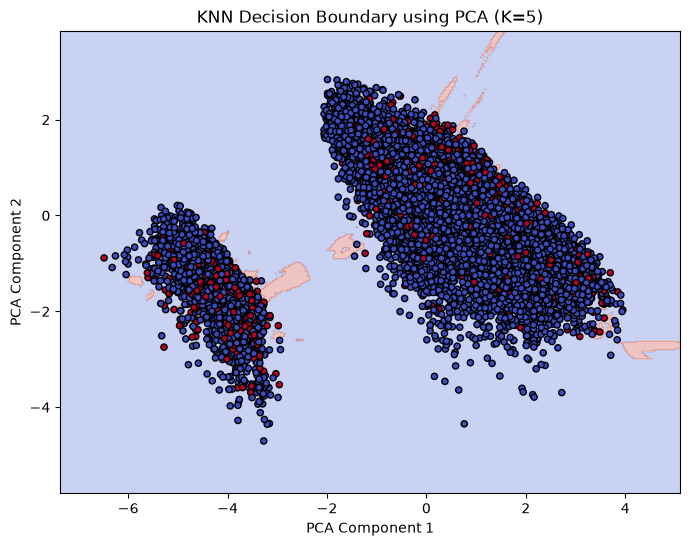

In [23]:
plt.figure(figsize=(8, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

plt.scatter(
    X_test_pca[:, 0],
    X_test_pca[:, 1],
    c=y_test,
    cmap='coolwarm',
    edgecolors='k',
    s=20
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("KNN Decision Boundary using PCA (K=5)")

plt.show()

Testing different Values with PCA

In [24]:
pca_results = []

for k in [1, 3, 5, 7, 10, 15, 20]:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_pca, y_train)

    y_pred = model.predict(X_test_pca)
    y_prob = model.predict_proba(X_test_pca)[:, 1]

    pca_results.append({
        'K': k,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_test, y_prob)
    })

pca_results_df = pd.DataFrame(pca_results)

print("\nPCA + KNN Results:")
print(pca_results_df.round(2))


PCA + KNN Results:
    K  Accuracy  Precision  Recall    F1  ROC_AUC
0   1      0.81       0.13    0.13  0.13     0.51
1   3      0.86       0.15    0.06  0.08     0.53
2   5      0.88       0.18    0.03  0.05     0.54
3   7      0.88       0.23    0.02  0.04     0.55
4  10      0.89       0.48    0.01  0.01     0.56
5  15      0.89       0.45    0.00  0.01     0.58
6  20      0.89       0.17    0.00  0.00     0.59


SMOTE

In [26]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Suitability
0    68445
1     8698
Name: count, dtype: int64

After SMOTE:
Suitability
1    68445
0    68445
Name: count, dtype: int64


SMOTE + KNN Cross Validation

In [29]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

k_values = [1, 3, 5, 7, 10, 15, 20]

smote_cv_results = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for k in k_values:

    pipeline = Pipeline([
        ('smote', SMOTE(random_state=42)),
        ('knn', KNeighborsClassifier(
            n_neighbors=k,
            n_jobs=-1
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X_train_scaled,
        y_train,
        cv=cv,
        scoring='f1',
        n_jobs=-1
    )

    smote_cv_results.append({
        'K': k,
        'Mean F1': scores.mean(),
        'Std F1': scores.std()
    })

smote_cv_results_df = pd.DataFrame(smote_cv_results)

print("\nSMOTE + KNN Cross-Validation Results:")
print(smote_cv_results_df.round(3))



SMOTE + KNN Cross-Validation Results:
    K  Mean F1  Std F1
0   1    0.321   0.007
1   3    0.334   0.006
2   5    0.335   0.007
3   7    0.334   0.007
4  10    0.340   0.005
5  15    0.336   0.003
6  20    0.342   0.004


Comaparing all Methods

In [31]:
results_df['Method'] = 'Scaling + KNN'

pca_results_df['Method'] = 'Scaling + PCA + KNN'

smote_cv_results_df['Method'] = 'Scaling + SMOTE + KNN'

comparison_df = pd.concat(
    [results_df, pca_results_df, smote_cv_results_df],
    ignore_index=True
)

print("\nFinal Comparison:")
print(comparison_df.round(2))


Final Comparison:
     K  Accuracy  Precision  Recall    F1  ROC_AUC                 Method  \
0    1      0.84       0.32    0.33  0.32     0.62          Scaling + KNN   
1    3      0.87       0.38    0.24  0.29     0.68          Scaling + KNN   
2    5      0.88       0.42    0.19  0.26     0.71          Scaling + KNN   
3    7      0.88       0.44    0.15  0.22     0.73          Scaling + KNN   
4   10      0.89       0.57    0.10  0.17     0.75          Scaling + KNN   
5   15      0.89       0.58    0.11  0.19     0.76          Scaling + KNN   
6   20      0.89       0.66    0.09  0.16     0.78          Scaling + KNN   
7    1      0.81       0.13    0.13  0.13     0.51    Scaling + PCA + KNN   
8    3      0.86       0.15    0.06  0.08     0.53    Scaling + PCA + KNN   
9    5      0.88       0.18    0.03  0.05     0.54    Scaling + PCA + KNN   
10   7      0.88       0.23    0.02  0.04     0.55    Scaling + PCA + KNN   
11  10      0.89       0.48    0.01  0.01     0.56    Sca

Select best K from Cross Validation

In [32]:
best_smote_k = smote_cv_results_df.loc[
    smote_cv_results_df['Mean F1'].idxmax(),
    'K'
]

print("Best K:", int(best_smote_k))

Best K: 20


Final KNN Model

In [33]:
final_smote_knn = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('knn', KNeighborsClassifier(
        n_neighbors=int(best_smote_k),
        n_jobs=-1
    ))
])

final_smote_knn.fit(X_train_scaled, y_train)

final_smote_pred = final_smote_knn.predict(X_test_scaled)

Final Results

In [35]:
print("\n===================================")
print("FINAL KNN RESULTS")
print("===================================")

print("Selected K:", int(best_smote_k))

print(
 "Accuracy:",accuracy_score(y_test, final_smote_pred))

print(
    "Precision:",precision_score(y_test,final_smote_pred,zero_division=0))

print(
    "Recall:",recall_score(y_test,final_smote_pred,zero_division=0))

print(
    "F1 Score:",f1_score(y_test,final_smote_pred,zero_division=0))




FINAL KNN RESULTS
Selected K: 20
Accuracy: 0.6993674167790107
Precision: 0.22812546900795438
Recall: 0.6988505747126437
F1 Score: 0.343969223806291


Confusion Matrix

Confusion Matrix:
[[11968  5143]
 [  655  1520]]


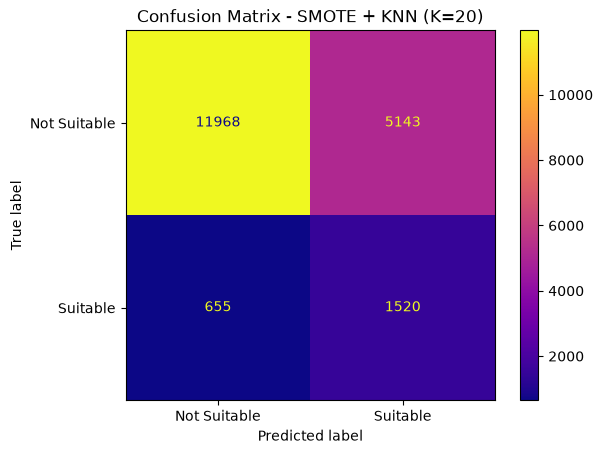

In [226]:
cm = confusion_matrix(y_test, final_smote_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Suitable", "Suitable"]
)

disp.plot(cmap=plt.cm.plasma)
plt.title(f"Confusion Matrix - SMOTE + KNN (K={int(best_smote_k)})")
plt.show()